# Spread Duration & CS01 by Asset Class

Once a treasury swaps its bonds to floating, interest-rate risk is mostly gone, but credit-spread risk is not: when spreads widen, the bonds lose value and the swaps do not move. How much that costs depends a lot on what the portfolio holds. This notebook measures spread risk sleeve by sleeve and replays the crises that would hurt most.

**What it does.** It measures the credit-spread risk of an MDB-style treasury portfolio sleeve by sleeve (agencies, USD sovereigns, sub-sovereigns, banks and corporates) and stresses it with historical and hypothetical spread scenarios.

**Data.** Live bond-level holdings of five iShares ETFs (GOVT, AGZ, EMB, MUB, IGIB), today's Treasury par curve (U.S. Treasury), three years of daily ICE BofA OAS by rating bucket and 40 years of Moody's Baa/Aaa spreads (FRED).

**Methods.** Spread duration, CS01 and duration-times-spread (DTS) per bond, regression betas of each rating bucket to the long-history Baa spread, and an empirical test of the DTS hypothesis.

Full-revaluation scenario P&L and historical spread VaR and ES complete the analysis.

**Key output.** CS01 and DTS by sleeve against limits, crisis-replay losses (2008, 2011, 2020, 2022), parallel and proportional spread shocks, spread VaR, and a spread-risk dashboard.

## 1. Why spread risk needs its own report

An MDB swaps its bond portfolio to floating, so rate risk is largely hedged. What the swaps do **not** hedge is the **credit spread** of each bond over the risk-free curve. When spreads widen, the bonds lose value while the swaps don't move. For a liquidity portfolio this is the main residual market risk, and it differs a lot by asset class:

- **Agencies and supranationals:** near-sovereign, with small and stable spreads.
- **USD sovereigns:** tight for strong credits, but they jump on country events.
- **Sub-sovereigns (US states and municipalities):** their low pre-tax yields reflect US tax exemption, and their spreads move with their own market.
- **Banks and corporates:** the widest spreads and the most cyclical.

The risk officer's questions: how much do we lose per basis point of widening in each sleeve (**CS01**)? Which sleeve's spreads are most volatile (**DTS**)? And what would a 2008- or 2020-style widening cost us?

## 2. The measures

With $P(s)$ the dirty price discounted on the Treasury zero curve plus a Z-spread $s$:

| Measure | Definition | Reads as |
|---|---|---|
| Spread duration | $SD = \frac{P(s-\Delta) - P(s+\Delta)}{2P\,\Delta}$ | % price change per unit of spread widening |
| CS01 | $P(s) - P(s + 1\text{bp})$, in dollars held | dollars lost per +1 bp of spread |
| DTS | $SD \times s$ | spread risk adjusted for spread level |

For a fixed-rate bullet bond spread duration is close to rate duration. They differ for floaters, which have little rate duration but full spread duration.

**Why DTS.** Spread changes are roughly *proportional* to spread levels: a bond at 300 bp typically moves three times as much as one at 100 bp. If that holds, $\Delta s_i \approx s_i\,\varepsilon$ with a common relative shock $\varepsilon$, and the P&L is $-SD_i \cdot s_i \cdot \varepsilon = -DTS_i\,\varepsilon$.

DTS rather than CS01 then becomes the comparable risk measure across sleeves (Ben Dor et al., 2007). Section 6 tests this on the data.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import statsmodels.api as sm
from scipy.optimize import brentq

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# --- Portfolio design
PORTFOLIO_SIZE_USD = 1_000_000_000
SLEEVE_TARGETS = {
    "US Treasuries": 0.35,
    "Agencies": 0.15,
    "Sovereigns": 0.10,
    "Sub-sovereigns": 0.10,
    "Banks": 0.15,
    "Corporates": 0.15,
}
BONDS_PER_SLEEVE = 30
MATURITY_RANGE_Y = (1.0, 30.0)
KEY_TENORS = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
# investment-grade proxy for USD sovereigns (EMB has no rating column)
SOVEREIGN_MAX_SPREAD_BP = 200

# --- Spread-risk settings
SPREAD_BUMP_BP = 25
CREDIT_SLEEVES = [
    "Agencies",
    "Sovereigns",
    "Sub-sovereigns",
    "Banks",
    "Corporates",
]
# Market proxy for each sleeve's spread: ICE BofA option-adjusted spread
# indices (FRED)
SLEEVE_INDEX = {
    "Agencies": "BAMLC0A1CAAA",  # US Corporate AAA
    # EM IG (USD) Corporate Plus, closest free EM IG series
    "Sovereigns": "BAMLEMIBHGCRPIOAS",
    "Sub-sovereigns": "BAMLC0A2CAA",  # US Corporate AA
    "Banks": "BAMLC0A3CA",  # US Corporate A
    "Corporates": "BAMLC0A4CBBB",
}  # US Corporate BBB
# Hypothetical CS01 limits by sleeve ($ thousands per bp), as a credit officer
# would set them
CS01_LIMITS_K = {
    "Agencies": 70,
    "Sovereigns": 60,
    "Sub-sovereigns": 110,
    "Banks": 120,
    "Corporates": 120,
}

print(
    f"QuantLib {ql.__version__} · statsmodels {sm.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · statsmodels 0.15.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 4. Data

### 4.1 Bonds: iShares holdings

| Sleeve | ETF | Product id |
|---|---|---|
| US Treasuries | GOVT | 239468 |
| Agencies | AGZ | 239457 |
| Sovereigns (USD) | EMB, J.P. Morgan USD Emerging Markets Bond | 239572 |
| Sub-sovereigns | MUB (US states and municipalities) | 239766 |
| Banks / Corporates | IGIB (split by sector) | 239463 |

The EMB file has no rating column. Because an MDB liquidity portfolio holds only investment-grade sovereigns, we keep EMB bonds with a yield pick-up over Treasuries of at most 200 bp, a transparent proxy for investment grade. EMB's quasi-sovereign agencies are excluded, so the sleeve holds central-government bonds only.

In [3]:
ISHARES_FUNDS = {
    "GOVT": "239468",
    "AGZ": "239457",
    "EMB": "239572",
    "MUB": "239766",
    "IGIB": "239463",
}
SLEEVE_BY_FUND = {
    "GOVT": "US Treasuries",
    "AGZ": "Agencies",
    "EMB": "Sovereigns",
    "MUB": "Sub-sovereigns",
}


def fetch_holdings(ticker: str) -> pd.DataFrame:
    """
    Download one iShares fund's holdings file and return the holdings table as
    text columns.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=30
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    table = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    table["fund"], table["as_of"] = ticker, as_of
    return table


raw_holdings = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)


def to_number(s):
    """'1,234.50' -> 1234.5 ; '-' or '' -> NaN."""
    return pd.to_numeric(
        s.astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )


col = lambda name, default="": (
    raw_holdings[name]
    if name in raw_holdings
    else pd.Series(default, index=raw_holdings.index)
)
bonds = pd.DataFrame({
    "fund": raw_holdings["fund"],
    "name": raw_holdings["Name"],
    "sector": col("Sector").fillna(""),
    "asset_class": col("Asset Class").fillna(""),
    "currency": col("Currency", "USD").fillna(""),
    "isin": col("ISIN"),
    "weight_pct": to_number(raw_holdings["Weight (%)"]),
    "clean_price": to_number(col("Price", np.nan)),
    "coupon_pct": to_number(raw_holdings["Coupon (%)"]),
    "ishares_duration": to_number(col("Duration", np.nan)),
    "ishares_ytm_pct": to_number(col("YTM (%)", np.nan)),
    "maturity": pd.to_datetime(
        raw_holdings["Maturity"], format="%b %d, %Y", errors="coerce"
    ).fillna(
        pd.to_datetime(
            raw_holdings["Maturity"], format="mixed", errors="coerce"
        )
    ),
    "as_of": raw_holdings["as_of"],
})
# Sleeve = the fund it came from; the corporate fund is split into banks and
# other corporates by sector
bonds["sleeve"] = [
    SLEEVE_BY_FUND.get(f)
    or ("Banks" if re.search("bank", s, re.I) else "Corporates")
    for f, s in zip(bonds["fund"], bonds["sector"])
]


def clean_price_from_ytm(coupon_pct, ytm_pct, maturity, settle):
    """
    Clean price per 100 from a semi-annual yield, used when a holdings file has
    no Price column.
    """
    if (
        any(pd.isna(v) for v in (coupon_pct, ytm_pct, maturity, settle))
        or maturity <= settle
    ):
        return np.nan
    c, y = coupon_pct / 2, ytm_pct / 200
    # coupon dates, walking back from maturity
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfs = dates[-1], sorted(dates[:-1])
    # fraction of the first period still to run
    frac = (cfs[0] - settle).days / (cfs[0] - prev).days
    dirty = sum(c / (1 + y) ** (frac + k) for k in range(len(cfs))) + 100 / (
        1 + y
    ) ** (frac + len(cfs) - 1)
    # remove accrued interest
    return dirty - c * (1 - frac)


missing_price = bonds["clean_price"].isna() & bonds["ishares_ytm_pct"].notna()
settle = pd.to_datetime(bonds["as_of"], format="%b %d, %Y", errors="coerce")
bonds.loc[missing_price, "clean_price"] = [
    clean_price_from_ytm(c, y, m, s)
    for c, y, m, s in zip(
        bonds.loc[missing_price, "coupon_pct"],
        bonds.loc[missing_price, "ishares_ytm_pct"],
        bonds.loc[missing_price, "maturity"],
        settle[missing_price],
    )
]
if missing_price.any():
    print(
        "Clean price rebuilt from iShares YTM for"
        f" {missing_price.sum()} holdings"
        f" ({', '.join(bonds.loc[missing_price, 'fund'].unique())}: file has"
        " no Price column)"
    )
print(
    f"{len(bonds):,} holdings parsed · "
    + ", ".join(f"{f} {n:,}" for f, n in bonds["fund"].value_counts().items())
)

Clean price rebuilt from iShares YTM for 119 holdings (AGZ: file has no Price column)
11,626 holdings parsed · MUB 7,604, IGIB 3,053, EMB 619, GOVT 231, AGZ 119


### 4.2 Treasury curve

In [4]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    """
    Daily Treasury par yield curves for the current year (falls back to last
    year in early January).
    """
    get = lambda year: pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    raw = get(dt.date.today().year)
    if len(raw) < 20:  # early January: add last year's file
        raw = pd.concat(
            [raw, get(dt.date.today().year - 1)], ignore_index=True
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

FRED_KEY_SERIES = {
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_history():
    frames = []
    for sid, tenor in FRED_KEY_SERIES.items():
        s = fred.get_series(
            sid, observation_start=EVAL_DATE - pd.Timedelta(days=3653)
        ).dropna()
        frames.append(
            pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        )
    return pd.concat(frames, ignore_index=True)


history = (
    cached("fred_treasury_key_rates", fetch_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()[list(KEY_TENORS)]
    .dropna()
)
daily_changes_bp = history.diff().dropna() * 100
print(
    f"Evaluation date {EVAL_DATE:%Y-%m-%d} · {len(daily_changes_bp):,} daily"
    f" curve moves ({daily_changes_bp.index.min():%Y} →"
    f" {daily_changes_bp.index.max():%Y})"
)

Evaluation date 2026-10-16 · 2,498 daily curve moves (2016 → 2026)


### 4.3 Spread history

- **ICE BofA option-adjusted spreads by rating** (FRED `BAMLC0A1CAAA`, `BAMLC0A2CAA`, `BAMLC0A3CA`, `BAMLC0A4CBBB`, `BAMLEMIBHGCRPIOAS`). FRED carries only the last three years of these indices.
- **Moody's seasoned Baa and Aaa corporate yields minus the 10Y Treasury** (FRED `BAA10Y`, `AAA10Y`, daily since 1986). They are the long history that lets us replay 2008, 2011, 2020 and 2022.

In [5]:
def fetch_spreads():
    ids = sorted(
        set(SLEEVE_INDEX.values()) | {"BAMLC0A0CM", "BAA10Y", "AAA10Y"}
    )
    frames = [
        pd.DataFrame({"date": s.index, "series": sid, "spread_pct": s.values})
        for sid in ids
        for s in [fred.get_series(sid).dropna()]
    ]
    return pd.concat(frames, ignore_index=True)


spreads = (
    cached("fred_credit_spreads", fetch_spreads).pivot(
        index="date", columns="series", values="spread_pct"
    )
    * 100
)
spreads = spreads.sort_index()  # bp
ice = spreads[list(SLEEVE_INDEX.values()) + ["BAMLC0A0CM"]].dropna()
moody = spreads[["BAA10Y", "AAA10Y"]].dropna()
print(
    f"ICE OAS: {ice.index.min():%Y-%m-%d} →"
    f" {ice.index.max():%Y-%m-%d} ({len(ice):,} days) · Moody's:"
    f" {moody.index.min():%Y} → {moody.index.max():%Y} ({len(moody):,} days)"
)
ice.iloc[-1].rename("today (bp)").to_frame().T.round(0)

ICE OAS: 2023-10-20 → 2026-10-16 (783 days) · Moody's: 1986 → 2026 (10,197 days)


series,BAMLC0A1CAAA,BAMLEMIBHGCRPIOAS,BAMLC0A2CAA,BAMLC0A3CA,BAMLC0A4CBBB,BAMLC0A0CM
today (bp),41.00,93.00,61.00,71.00,106.00,85.00


## 5. Portfolio and spread measures

An MDB-style liquidity portfolio of real bonds, with an extra sovereign sleeve. The investment-grade filter for sovereigns is applied before selection. Every bond is priced on the Treasury zero curve plus its own Z-spread, then the **spread** alone is bumped with the Treasury curve held fixed.

In [6]:
# Investment-grade proxy for USD sovereigns: yield pick-up over the Treasury
# par curve at the same maturity
ytm_gap_bp = (
    bonds["ishares_ytm_pct"]
    - np.interp(
        (
            bonds["years_to_maturity"]
            if "years_to_maturity" in bonds
            else (bonds["maturity"] - EVAL_DATE).dt.days / 365.25
        ),
        par_today.index.values,
        par_today.values,
    )
) * 100
is_sov = bonds["sleeve"].eq("Sovereigns")
keep = ~is_sov | (
    bonds["sector"].eq("Sovereign") & ytm_gap_bp.le(SOVEREIGN_MAX_SPREAD_BP)
)
print(
    f"Sovereigns: {is_sov.sum()} EMB holdings →"
    f" {(is_sov & keep).sum()} central-government bonds within"
    f" {SOVEREIGN_MAX_SPREAD_BP} bp of Treasuries"
)
bonds = bonds[keep].copy()

Sovereigns: 619 EMB holdings → 352 central-government bonds within 200 bp of Treasuries


In [7]:
today = EVAL_DATE.normalize()
bonds["years_to_maturity"] = (bonds["maturity"] - today).dt.days / 365.25
eligible = bonds[
    bonds["currency"].eq("USD")
    & bonds["clean_price"].gt(0)
    & bonds["coupon_pct"].notna()
    & bonds["years_to_maturity"].between(*MATURITY_RANGE_Y)
    & ~bonds["asset_class"].str.contains(
        "Cash|Money Market|Futures", case=False
    )
    & bonds["sleeve"].isin(SLEEVE_TARGETS)
].copy()

# The largest holdings of each sleeve, re-weighted to the sleeve's target share
# of the portfolio
portfolio = (
    eligible.sort_values("weight_pct", ascending=False)
    .groupby("sleeve", group_keys=False)
    .head(BONDS_PER_SLEEVE)
    .copy()
)
portfolio["market_value"] = (
    portfolio.groupby("sleeve")["weight_pct"].transform(lambda w: w / w.sum())
    * portfolio["sleeve"].map(SLEEVE_TARGETS)
    * PORTFOLIO_SIZE_USD
)
portfolio = portfolio.reset_index(drop=True)
SLEEVE_COLORS = dict(zip(SLEEVE_TARGETS, PALETTE))

portfolio.groupby("sleeve").agg(
    bonds=("name", "size"),
    market_value_mm=("market_value", lambda v: v.sum() / 1e6),
    avg_coupon_pct=("coupon_pct", "mean"),
    avg_maturity_y=("years_to_maturity", "mean"),
).reindex(SLEEVE_TARGETS)

# Distinct colours for six sleeves (the default palette order puts two greens
# side by side)
SLEEVE_COLORS = {
    "US Treasuries": "#52514e",
    "Agencies": "#eb6834",
    "Sovereigns": "#6250d6",
    "Sub-sovereigns": "#eda100",
    "Banks": "#e87ba4",
    "Corporates": "#2a78d6",
}

In [8]:
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)


def build_treasury_curve(par_row):
    """
    Bootstrap a Treasury zero curve from one day's par yields (bills as zeros,
    notes/bonds at par).
    """
    helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
    for tenor, par_yield in par_row.items():
        y = par_yield / 100
        period = (
            ql.Period(int(round(tenor * 52)), ql.Weeks)
            if tenor < 1
            else ql.Period(int(round(tenor * 12)), ql.Months)
        )
        maturity = US_GOVT.advance(ql_today, period)
        freq, coupons, price = (
            (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
            if tenor <= 1
            else (ql.Semiannual, [y], 100.0)
        )
        schedule = ql.Schedule(
            ql_today,
            maturity,
            ql.Period(freq),
            US_GOVT,
            ql.Unadjusted,
            ql.Unadjusted,
            ql.DateGeneration.Backward,
            False,
        )
        helpers.append(
            ql.FixedRateBondHelper(
                ql.QuoteHandle(ql.SimpleQuote(price)),
                0,
                100.0,
                schedule,
                coupons,
                bond_dc,
            )
        )
    curve = ql.PiecewiseConvexMonotoneForward(
        ql_today, helpers, ql.Actual365Fixed()
    )
    curve.enableExtrapolation()
    return curve


ust_curve = build_treasury_curve(par_today)
GRID_T = np.linspace(1 / 365, 31, 31 * 52)
# continuous zero rates
GRID_Z = np.array(
    [ust_curve.zeroRate(float(t), ql.Continuous).rate() for t in GRID_T]
)


def zero_rate(t):
    """
    Treasury zero rate (decimal, continuous) at times t (years), by
    interpolation on the grid.
    """
    return np.interp(t, GRID_T, GRID_Z)


def cash_flows(coupon_pct, years_to_maturity):
    """
    Times (years) and amounts per 100 face of a semi-annual fixed-coupon bond.
    """
    times = np.arange(years_to_maturity, 0, -0.5)[::-1]
    amounts = np.full(len(times), coupon_pct / 2)
    amounts[-1] += 100
    return times, amounts


def price_from_curve(times, amounts, spread, shift=None, zero=None):
    """
    Dirty price per 100 face on a zero curve + constant spread (+ an optional
    bump function of t).
    """
    z = (
        (zero_rate(times) if zero is None else zero(times))
        + spread
        + (0 if shift is None else shift(times))
    )
    return float(np.sum(amounts * np.exp(-z * times)))


records = []
for i, b in portfolio.iterrows():
    times, amounts = cash_flows(b["coupon_pct"], b["years_to_maturity"])
    # linear accrual since the last coupon
    accrued = b["coupon_pct"] / 2 * (1 - times[0] / 0.5)
    dirty = b["clean_price"] + accrued
    try:
        z_spread = brentq(
            lambda s: price_from_curve(times, amounts, s) - dirty, -0.05, 0.20
        )
    # price outside any reasonable spread (bad print): dropped below
    except ValueError:
        z_spread = np.nan
    records.append({
        "times": times,
        "amounts": amounts,
        "accrued": accrued,
        "dirty_price": dirty,
        "z_spread_bp": z_spread * 1e4,
    })

portfolio = pd.concat([portfolio, pd.DataFrame(records)], axis=1)
dropped = portfolio["z_spread_bp"].isna().sum()
portfolio = portfolio.dropna(subset=["z_spread_bp"]).reset_index(drop=True)
# USD face amount held
portfolio["face"] = portfolio["market_value"] / portfolio["dirty_price"] * 100
print(
    f"Treasury zero curve: "
    + ", ".join(
        f"{tenor_label(t)} {zero_rate(t)*100:.2f}%"
        for t in (0.5, 2, 5, 10, 30)
    )
    + (
        f" · {dropped} bond(s) dropped (price inconsistent with any spread)"
        if dropped
        else ""
    )
)

Treasury zero curve: 6M 4.31%, 2Y 4.69%, 5Y 4.84%, 10Y 5.06%, 30Y 5.41%


In [9]:
d = SPREAD_BUMP_BP / 1e4
rows = []
for _, b in portfolio.iterrows():
    t, cf, s = b["times"], b["amounts"], b["z_spread_bp"] / 1e4
    p0, p_up, p_dn = (price_from_curve(t, cf, s + x) for x in (0.0, d, -d))
    sd = (p_dn - p_up) / (2 * p0 * d)
    rows.append({
        "spread_duration": sd,
        "spread_convexity": (p_up + p_dn - 2 * p0) / (p0 * d**2),
        "cs01_usd": (p0 - price_from_curve(t, cf, s + 1e-4)) * b["face"] / 100,
        # DTS = spread duration × spread (%); undefined when the
        # spread is negative (tax-exempt munis)
        "dts": sd * b["z_spread_bp"] / 100 if b["z_spread_bp"] > 0 else np.nan,
    })
risk = pd.concat(
    [portfolio.drop(columns=["times", "amounts"]), pd.DataFrame(rows)], axis=1
)


def sleeve_view(g):
    w = g["market_value"]
    return pd.Series({
        "bonds": len(g),
        "market_value_mm": w.sum() / 1e6,
        "z_spread_bp": np.average(g["z_spread_bp"], weights=w),
        "spread_duration": np.average(g["spread_duration"], weights=w),
        "DTS": (
            np.average(g["dts"].dropna(), weights=w[g["dts"].notna()])
            if g["dts"].notna().mean() > 0.5
            else np.nan
        ),
        "CS01_$k": g["cs01_usd"].sum() / 1e3,
    })


by_sleeve = (
    risk.groupby("sleeve")
    .apply(sleeve_view, include_groups=False)
    .reindex(SLEEVE_TARGETS)
)
by_sleeve.loc["Portfolio"] = sleeve_view(risk)
credit_cs01 = by_sleeve.loc[CREDIT_SLEEVES, "CS01_$k"].sum()
by_sleeve["share_of_credit_CS01_%"] = by_sleeve["CS01_$k"] / credit_cs01 * 100
by_sleeve.loc[["US Treasuries", "Portfolio"], "share_of_credit_CS01_%"] = (
    np.nan
)
by_sleeve.round(2)

,bonds,market_value_mm,z_spread_bp,spread_duration,DTS,CS01_$k,share_of_credit_CS01_%
sleeve,,,,,,,
US Treasuries,30.00,350.00,1.67,5.07,0.09,177.31,NaN
Agencies,30.00,150.00,13.03,3.41,0.49,51.21,12.33
Sovereigns,30.00,100.00,82.54,6.90,7.46,68.92,16.59
Sub-sovereigns,30.00,100.00,-74.20,9.42,NaN,94.11,22.65
Banks,30.00,150.00,83.16,6.71,5.65,100.62,24.22
Corporates,30.00,150.00,109.71,6.71,7.38,100.60,24.21
Portfolio,180.00,"1,000.00",32.30,5.93,3.41,592.77,NaN


The Treasury sleeve has a CS01 by construction, but its "spread" is only the residual against our fitted curve: there is no credit risk to stress. It is left out of all spread scenarios below.

How do our sleeves compare with the market indices? The portfolio Z-spreads are measured over Treasuries, as the ICE option-adjusted spreads are, so the two are directly comparable.

In [10]:
index_today = ice.iloc[-1]
compare = pd.DataFrame({
    "portfolio Z-spread (bp)": by_sleeve.loc[CREDIT_SLEEVES, "z_spread_bp"],
    "proxy index": [SLEEVE_INDEX[s] for s in CREDIT_SLEEVES],
    "index OAS today (bp)": [
        index_today[SLEEVE_INDEX[s]] for s in CREDIT_SLEEVES
    ],
})
compare["difference (bp)"] = (
    compare["portfolio Z-spread (bp)"] - compare["index OAS today (bp)"]
)
compare.round(1)

,portfolio Z-spread (bp),proxy index,index OAS today (bp),difference (bp)
sleeve,,,,
Agencies,13.00,BAMLC0A1CAAA,41.00,-28.00
Sovereigns,82.50,BAMLEMIBHGCRPIOAS,93.00,-10.50
Sub-sovereigns,-74.20,BAMLC0A2CAA,61.00,-135.20
Banks,83.20,BAMLC0A3CA,71.00,12.20
Corporates,109.70,BAMLC0A4CBBB,106.00,3.70


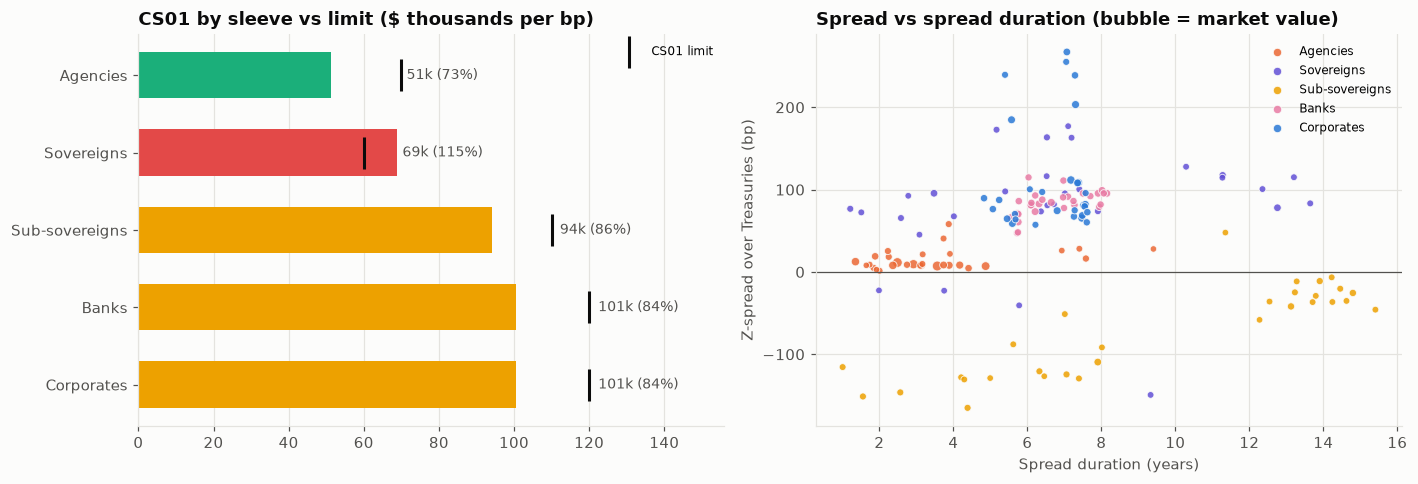

In [11]:
# --- Chart 1: where the spread risk sits
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
cs = by_sleeve.loc[CREDIT_SLEEVES, "CS01_$k"]
lim = pd.Series(CS01_LIMITS_K)[CREDIT_SLEEVES]
colors = [
    (
        STATUS["red"]
        if v > l
        else STATUS["amber"] if v > 0.8 * l else STATUS["green"]
    )
    for v, l in zip(cs, lim)
]
ax.barh(CREDIT_SLEEVES[::-1], cs.values[::-1], color=colors[::-1], height=0.6)
ax.scatter(
    lim.values[::-1],
    CREDIT_SLEEVES[::-1],
    marker="|",
    s=420,
    color=INK,
    lw=2,
    label="CS01 limit",
    zorder=3,
)
for y, (v, l) in enumerate(zip(cs.values[::-1], lim.values[::-1])):
    ax.text(
        max(v, l) * 1.02,
        y,
        f"{v:,.0f}k ({v / l:.0%})",
        va="center",
        fontsize=9,
        color=INK_2,
    )
ax.set_xlim(0, max(cs.max(), lim.max()) * 1.3)
ax.set_title("CS01 by sleeve vs limit ($ thousands per bp)")
ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="y", visible=False)

ax = axes[1]
credit = risk[risk["sleeve"].isin(CREDIT_SLEEVES)]
for sleeve in CREDIT_SLEEVES:
    g = credit[credit["sleeve"] == sleeve]
    ax.scatter(
        g["spread_duration"],
        g["z_spread_bp"],
        s=12 + g["market_value"] / 1e6 * 2.5,
        color=SLEEVE_COLORS[sleeve],
        alpha=0.85,
        edgecolor=SURFACE,
        lw=0.6,
        label=sleeve,
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Spread vs spread duration (bubble = market value)")
ax.set_xlabel("Spread duration (years)")
ax.set_ylabel("Z-spread over Treasuries (bp)")
leg = ax.legend(fontsize=8)
for h in leg.legend_handles:
    h.set_sizes([30])
plt.tight_layout()
save_fig(fig, "01_cs01_and_spread_map")
plt.show()

## 6. How do spreads move? Betas and the DTS test

Two questions the scenarios depend on:

1. **Betas.** How much does each rating bucket move when the long-history Moody's Baa spread moves? We regress weekly changes of each ICE bucket on weekly changes in `BAA10Y` over the three years where both exist. The betas then translate any Baa episode since 1986 into a move for each of our sleeves.
2. **DTS.** If spread changes are proportional to spread levels, the volatility of *relative* changes $\Delta s/s$ should be similar across buckets, while absolute volatility rises with the spread. And the betas should be close to the ratio of spread levels $s_{bucket}/s_{Baa}$.

The table and chart below give a split verdict, and the reading under the chart explains it.

In [12]:
weekly = spreads.resample("W-FRI").last()
w_ice = weekly[list(SLEEVE_INDEX.values())].dropna()
w_baa = weekly["BAA10Y"].reindex(w_ice.index)
d_ice, d_baa = w_ice.diff().dropna(), w_baa.diff().dropna()

beta_rows = []
for sleeve, sid in SLEEVE_INDEX.items():
    fit = sm.OLS(d_ice[sid], sm.add_constant(d_baa.loc[d_ice.index])).fit(
        cov_type="HAC", cov_kwds={"maxlags": 4}
    )
    rel = (w_ice[sid].diff() / w_ice[sid].shift()).dropna()
    beta_rows.append({
        "sleeve": sleeve,
        "index": sid,
        "beta_to_Baa": fit.params.iloc[1],
        "beta_se": fit.bse.iloc[1],
        "R2": fit.rsquared,
        "DTS_beta": w_ice[sid].mean() / w_baa.mean(),
        "abs_vol_bp_wk": d_ice[sid].std(),
        "rel_vol_%_wk": rel.std() * 100,
    })
betas = pd.DataFrame(beta_rows).set_index("sleeve")
BETA = betas["beta_to_Baa"].to_dict()
betas.round(3)

,index,beta_to_Baa,beta_se,R2,DTS_beta,abs_vol_bp_wk,rel_vol_%_wk
sleeve,,,,,,,
Agencies,BAMLC0A1CAAA,0.38,0.04,0.41,0.23,2.88,7.55
Sovereigns,BAMLEMIBHGCRPIOAS,0.61,0.06,0.43,0.62,4.51,4.37
Sub-sovereigns,BAMLC0A2CAA,0.43,0.05,0.51,0.32,2.92,5.56
Banks,BAMLC0A3CA,0.54,0.05,0.57,0.45,3.50,4.62
Corporates,BAMLC0A4CBBB,0.66,0.07,0.58,0.68,4.25,3.73


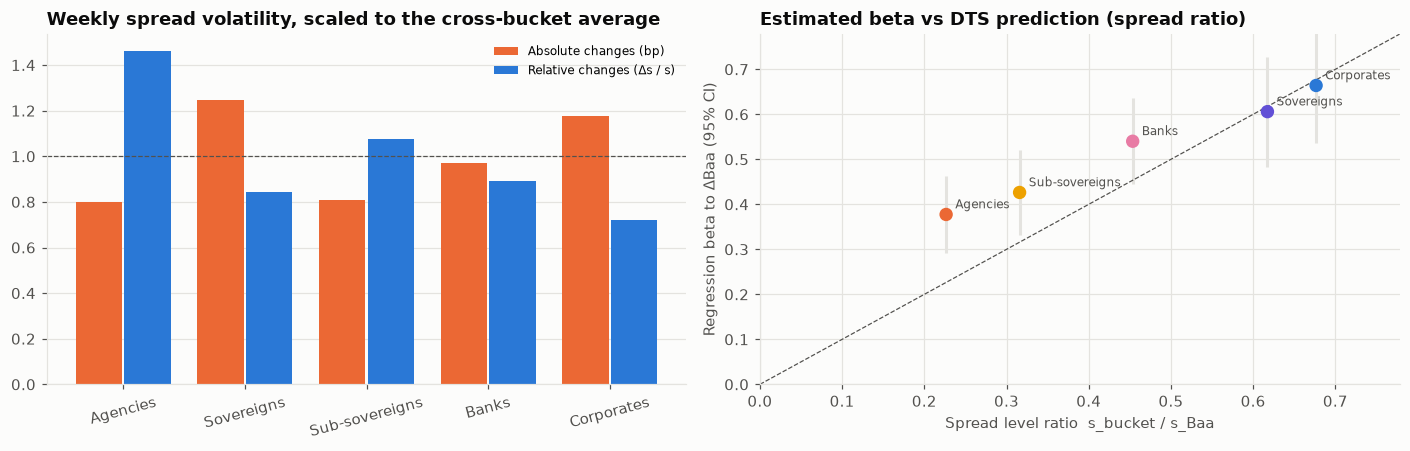

In [13]:
# --- Chart 2: the DTS test
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(betas))
ax = axes[0]
abs_n = betas["abs_vol_bp_wk"] / betas["abs_vol_bp_wk"].mean()
rel_n = betas["rel_vol_%_wk"] / betas["rel_vol_%_wk"].mean()
ax.bar(
    x - 0.2, abs_n, width=0.38, color=PALETTE[1], label="Absolute changes (bp)"
)
ax.bar(
    x + 0.2,
    rel_n,
    width=0.38,
    color=PALETTE[0],
    label="Relative changes (Δs / s)",
)
ax.axhline(1, color=INK_2, lw=0.8, ls="--")
ax.set_xticks(x, betas.index, rotation=15)
ax.set_title("Weekly spread volatility, scaled to the cross-bucket average")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.errorbar(
    betas["DTS_beta"],
    betas["beta_to_Baa"],
    yerr=1.96 * betas["beta_se"],
    fmt="none",
    ecolor=GRID,
    lw=2,
)
ax.scatter(
    betas["DTS_beta"],
    betas["beta_to_Baa"],
    s=60,
    color=[SLEEVE_COLORS[s] for s in betas.index],
    zorder=3,
)
for s, r in betas.iterrows():
    ax.annotate(
        s,
        (r["DTS_beta"], r["beta_to_Baa"]),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=8,
        color=INK_2,
    )
hi = max(betas["DTS_beta"].max(), betas["beta_to_Baa"].max()) * 1.15
ax.plot([0, hi], [0, hi], color=INK_2, lw=0.8, ls="--")
ax.set_xlim(0, hi)
ax.set_ylim(0, hi)
ax.set_title("Estimated beta vs DTS prediction (spread ratio)")
ax.set_xlabel("Spread level ratio  s_bucket / s_Baa")
ax.set_ylabel("Regression beta to ΔBaa (95% CI)")
plt.tight_layout()
save_fig(fig, "02_dts_test")
plt.show()

**Reading the test.** For the wider buckets (BBB corporates, EM IG) the regression betas sit right on the DTS prediction. For the tightest buckets (AAA, AA) the betas are clearly *above* the spread ratio, and their relative volatility is the highest of all. Near the floor, spreads do not shrink in proportion: a liquidity component that does not scale with credit quality keeps them moving.

That is why the historical replays below use the **estimated betas**, while the proportional scenarios use DTS logic and are a cross-check rather than the main tool.

## 7. Scenarios

All scenarios are applied by **full revaluation** of every bond, with the Treasury curve held fixed:

- **Parallel:** every credit sleeve widens by the same amount (+25, +50, +100 bp).
- **Proportional (DTS):** each sleeve widens in proportion to its market index spread today (+25%, +50%, +100%).
- **Historical replay:** the widening of the Moody's Baa spread from the start of each episode to its peak, translated into each sleeve with the regression betas.

In [14]:
CRISES = {
    "GFC 2007–08": ("2007-06-01", "2008-12-31"),
    "Euro crisis 2011": ("2011-04-01", "2011-12-31"),
    "COVID 2020": ("2020-02-14", "2020-04-30"),
    "Rate shock 2022": ("2022-01-03", "2022-10-31"),
}
crisis_rows = []
for name, (a, b) in CRISES.items():
    window = moody.loc[a:b, "BAA10Y"]
    crisis_rows.append({
        "episode": name,
        "start_bp": window.iloc[0],
        "peak_bp": window.max(),
        "peak_date": window.idxmax(),
        "widening_bp": window.max() - window.iloc[0],
    })
crises = pd.DataFrame(crisis_rows).set_index("episode")

SCENARIOS = {}
for x in (25, 50, 100):
    SCENARIOS[f"Parallel +{x} bp"] = {s: float(x) for s in CREDIT_SLEEVES}
for pct in (25, 50, 100):
    SCENARIOS[f"Proportional +{pct}%"] = {
        s: index_today[SLEEVE_INDEX[s]] * pct / 100 for s in CREDIT_SLEEVES
    }
for name, r in crises.iterrows():
    SCENARIOS[f"Replay: {name}"] = {
        s: BETA[s] * r["widening_bp"] for s in CREDIT_SLEEVES
    }


def scenario_pnl(shocks_bp):
    """
    Full-revaluation P&L by sleeve ($) for spread shocks given per sleeve (bp).
    """
    out = dict.fromkeys(CREDIT_SLEEVES, 0.0)
    for _, b in portfolio[portfolio["sleeve"].isin(CREDIT_SLEEVES)].iterrows():
        s = b["z_spread_bp"] / 1e4
        dp = price_from_curve(
            b["times"], b["amounts"], s + shocks_bp[b["sleeve"]] / 1e4
        ) - price_from_curve(b["times"], b["amounts"], s)
        out[b["sleeve"]] += dp * b["face"] / 100
    return out


scen = (
    pd.DataFrame({name: scenario_pnl(sh) for name, sh in SCENARIOS.items()}).T
    / 1e6
)
scen["Total"] = scen.sum(axis=1)
scen["linear CS01 estimate"] = [
    -sum(by_sleeve.loc[s, "CS01_$k"] * 1e3 * sh[s] for s in CREDIT_SLEEVES)
    / 1e6
    for sh in SCENARIOS.values()
]
scen["% of portfolio"] = scen["Total"] / (PORTFOLIO_SIZE_USD / 1e6) * 100
print(
    crises.round({"start_bp": 0, "peak_bp": 0, "widening_bp": 0}).to_string()
)
scen.round(2)

                  start_bp  peak_bp  peak_date  widening_bp
episode                                                    
GFC 2007–08         160.00   616.00 2008-12-04       456.00
Euro crisis 2011    258.00   339.00 2011-09-27        81.00
COVID 2020          204.00   431.00 2020-03-23       227.00
Rate shock 2022     182.00   242.00 2022-07-01        60.00


,Agencies,Sovereigns,Sub-sovereigns,Banks,Corporates,Total,linear CS01 estimate,% of portfolio
Parallel +25 bp,-1.27,-1.70,-2.31,-2.49,-2.49,-10.26,-10.39,-1.03
Parallel +50 bp,-2.53,-3.35,-4.53,-4.93,-4.93,-20.28,-20.77,-2.03
Parallel +100 bp,-5.01,-6.51,-8.72,-9.68,-9.68,-39.59,-41.55,-3.96
Proportional +25%,-0.52,-1.58,-1.42,-1.77,-2.64,-7.94,-8.01,-0.79
Proportional +50%,-1.05,-3.12,-2.80,-3.52,-5.22,-15.72,-16.03,-1.57
Proportional +100%,-2.08,-6.08,-5.48,-6.95,-10.24,-30.82,-32.06,-3.08
Replay: GFC 2007–08,-8.48,-16.35,-15.82,-22.53,-27.13,-90.31,-101.40,-9.03
Replay: Euro crisis 2011,-1.56,-3.29,-3.17,-4.33,-5.30,-17.64,-18.01,-1.76
Replay: COVID 2020,-4.30,-8.77,-8.46,-11.76,-14.31,-47.60,-50.48,-4.76
Replay: Rate shock 2022,-1.15,-2.45,-2.36,-3.22,-3.95,-13.14,-13.34,-1.31


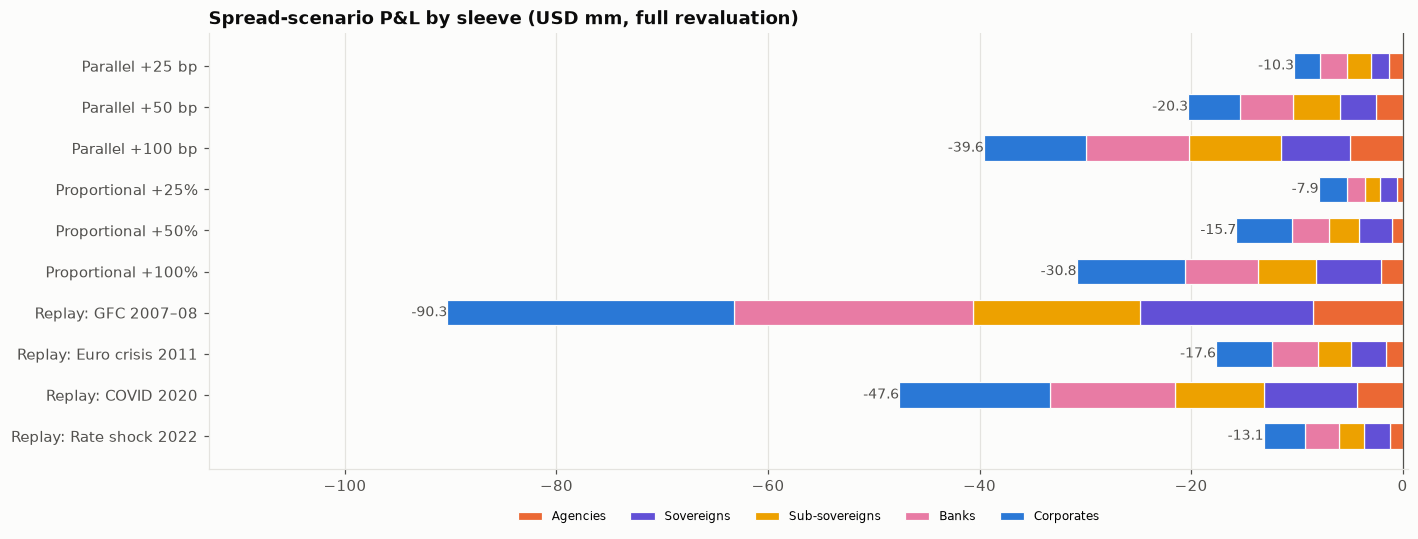

In [15]:
# --- Chart 3: scenario losses by sleeve
fig, ax = plt.subplots(figsize=(13, 5))
left = np.zeros(len(scen))
y = np.arange(len(scen))
for sleeve in CREDIT_SLEEVES:
    ax.barh(
        y,
        scen[sleeve],
        left=left,
        color=SLEEVE_COLORS[sleeve],
        height=0.62,
        label=sleeve,
        edgecolor=SURFACE,
        lw=0.8,
    )
    left += scen[sleeve].values
for yi, tot in zip(y, scen["Total"]):
    ax.text(
        tot,
        yi,
        f"  {tot:,.1f}",
        va="center",
        ha="left" if tot >= 0 else "right",
        fontsize=9,
        color=INK_2,
    )
ax.set_yticks(y, scen.index)
ax.invert_yaxis()
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("Spread-scenario P&L by sleeve (USD mm, full revaluation)")
ax.set_xlim(scen["Total"].min() * 1.25, max(0.5, scen["Total"].max()))
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.07), fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "03_scenario_pnl")
plt.show()

## 8. Spread VaR and ES

Historical simulation with the linear CS01 approximation, which section 7 shows is accurate for moves of this size: each day of the last three years applies the observed ICE bucket changes to the sleeves. Alongside it, a **stressed** version replays the daily Baa moves of the 2007–09 crisis through the betas, the FRTB-style answer to "what if the calm three years are not representative?".

In [16]:
cs01_vec = np.array(
    [by_sleeve.loc[s, "CS01_$k"] * 1e3 for s in CREDIT_SLEEVES]
)


def var_es(pnl, horizon=1):
    losses = -np.asarray(pnl) * np.sqrt(horizon)
    return (
        np.quantile(losses, 0.99),
        losses[losses >= np.quantile(losses, 0.975)].mean(),
    )


d_ice_daily = ice[[SLEEVE_INDEX[s] for s in CREDIT_SLEEVES]].diff().dropna()
pnl_hist = -(d_ice_daily.values @ cs01_vec)
d_baa_gfc = moody.loc["2007-06-01":"2009-06-30", "BAA10Y"].diff().dropna()
pnl_stress = (
    -np.outer(d_baa_gfc.values, [BETA[s] for s in CREDIT_SLEEVES]) @ cs01_vec
)

var_table = pd.DataFrame([
    {
        "measure": f"{label} · {h}-day",
        "VaR 99% ($mm)": v / 1e6,
        "ES 97.5% ($mm)": e / 1e6,
    }
    for label, p in [
        ("Historical (last 3y)", pnl_hist),
        ("Stressed (2007–09)", pnl_stress),
    ]
    for h in (1, 10)
    for v, e in [var_es(p, h)]
]).set_index("measure")
var_table.round(2)

,VaR 99% ($mm),ES 97.5% ($mm)
measure,,
Historical (last 3y) · 1-day,1.35,1.62
Historical (last 3y) · 10-day,4.26,5.13
Stressed (2007–09) · 1-day,4.18,4.51
Stressed (2007–09) · 10-day,13.23,14.26


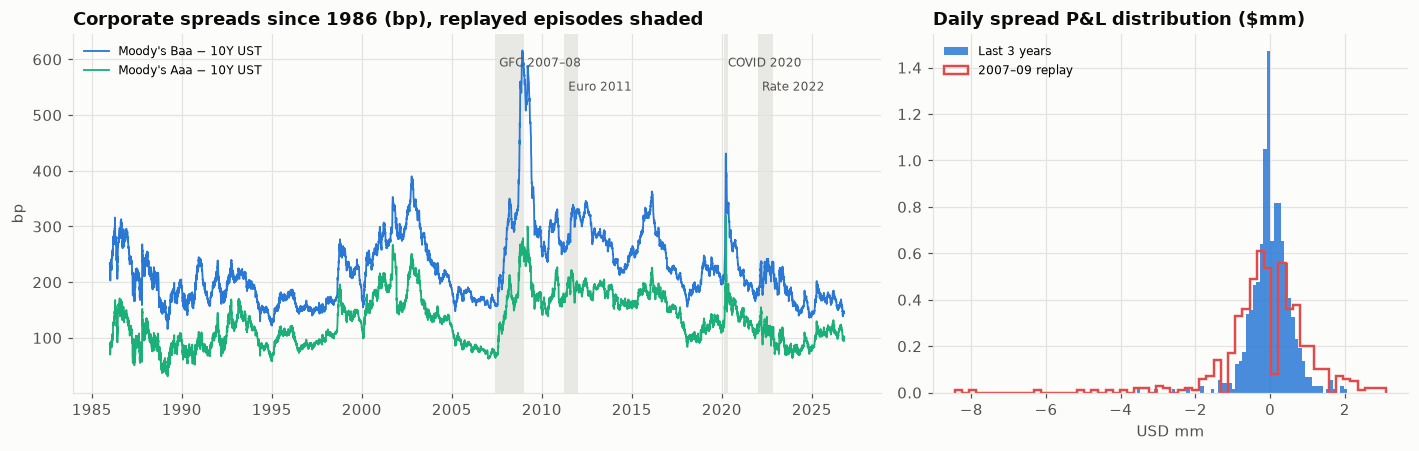

In [17]:
# --- Chart 4: 40 years of Baa spreads with the replayed episodes
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.7, 1]}
)
ax = axes[0]
ax.plot(
    moody.index,
    moody["BAA10Y"],
    color=PALETTE[0],
    lw=1.2,
    label="Moody's Baa − 10Y UST",
)
ax.plot(
    moody.index,
    moody["AAA10Y"],
    color=PALETTE[2],
    lw=1.2,
    label="Moody's Aaa − 10Y UST",
)
for j, (name, (a, b)) in enumerate(CRISES.items()):
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=GRID, alpha=0.8, lw=0)
    ax.text(
        pd.Timestamp(a),
        moody["BAA10Y"].max() * (0.98 - 0.07 * (j % 2)),
        " " + name.split()[0] + " " + name.split()[-1],
        fontsize=8,
        color=INK_2,
        va="top",
    )
ax.set_title("Corporate spreads since 1986 (bp), replayed episodes shaded")
ax.set_ylabel("bp")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
ax.hist(
    pnl_hist / 1e6,
    bins=60,
    color=PALETTE[0],
    alpha=0.85,
    density=True,
    label="Last 3 years",
)
ax.hist(
    pnl_stress / 1e6,
    bins=60,
    histtype="step",
    lw=1.6,
    color=STATUS["red"],
    density=True,
    label="2007–09 replay",
)
ax.set_title("Daily spread P&L distribution ($mm)")
ax.set_xlabel("USD mm")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "04_spread_history_and_var")
plt.show()

## 9. Spread-risk dashboard

In [18]:
util = (
    by_sleeve.loc[CREDIT_SLEEVES, "CS01_$k"]
    / pd.Series(CS01_LIMITS_K)[CREDIT_SLEEVES]
    * 100
)
light = lambda u: (
    "🔴 breach" if u > 100 else ("🟡 watch" if u > 80 else "🟢 within")
)
worst = scen["Total"].idxmin()

dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.13,
    horizontal_spacing=0.12,
    row_heights=[0.52, 0.48],
    specs=[[{}, {}], [{"type": "table", "colspan": 2}, None]],
    subplot_titles=(
        "CS01 by sleeve vs limit ($k per bp)",
        "Scenario P&L (USD mm)",
        "Spread-risk scorecard",
    ),
)
dash.add_trace(
    go.Bar(
        x=CREDIT_SLEEVES,
        y=by_sleeve.loc[CREDIT_SLEEVES, "CS01_$k"],
        showlegend=False,
        marker_color=[
            (
                STATUS["red"]
                if u > 100
                else STATUS["amber"] if u > 80 else STATUS["green"]
            )
            for u in util
        ],
        text=[f"{u:.0f}%" for u in util],
        textposition="outside",
        name="CS01",
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=CREDIT_SLEEVES,
        y=[CS01_LIMITS_K[s] for s in CREDIT_SLEEVES],
        mode="markers",
        marker=dict(
            symbol="line-ew-open", size=40, color=INK, line=dict(width=3)
        ),
        name="CS01 limit",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        y=scen.index[::-1],
        x=scen["Total"][::-1],
        orientation="h",
        showlegend=False,
        name="P&L",
        marker_color=[
            (
                STATUS["red"]
                if v < -15
                else STATUS["amber"] if v < -5 else PALETTE[0]
            )
            for v in scen["Total"][::-1]
        ],
    ),
    1,
    2,
)
tbl = by_sleeve.loc[CREDIT_SLEEVES]
dash.add_trace(
    go.Table(
        header=dict(
            values=[
                "Sleeve",
                "MV $mm",
                "Z-spread bp",
                "Spread dur.",
                "DTS",
                "CS01 $k/bp",
                "Limit $k",
                "Status",
                f"Worst scenario ({worst}) $mm",
            ],
            fill_color="#f1f0ec",
            font=dict(color=INK, size=11),
            align="left",
        ),
        cells=dict(
            values=[
                CREDIT_SLEEVES,
                tbl["market_value_mm"].round(0),
                tbl["z_spread_bp"].round(0),
                tbl["spread_duration"].round(2),
                [
                    f"{v:.2f}" if pd.notna(v) else "n/a (spread < 0)"
                    for v in tbl["DTS"]
                ],
                tbl["CS01_$k"].round(1),
                [CS01_LIMITS_K[s] for s in CREDIT_SLEEVES],
                [light(u) for u in util],
                scen.loc[worst, CREDIT_SLEEVES].round(1),
            ],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=11),
            align="left",
            height=26,
        ),
    ),
    2,
    1,
)
v1 = var_table.loc["Historical (last 3y) · 10-day", "VaR 99% ($mm)"]
v2 = var_table.loc["Stressed (2007–09) · 10-day", "VaR 99% ($mm)"]
dash.update_layout(
    height=900,
    width=1350,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=1.04, x=0),
    margin=dict(t=120, l=180),
    title=dict(
        x=0.01,
        text=(
            "<b>Credit-spread risk · MDB treasury portfolio ·"
            f" {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>Credit CS01"
            f" ${credit_cs01:,.0f}k/bp · 10-day spread VaR99 ${v1:,.1f}mm"
            f" (stressed ${v2:,.1f}mm) · worst scenario {worst}:"
            f" −${-scen.loc[worst, 'Total']:,.1f}mm</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")

risk.to_csv(OUT_DIR / "bond_spread_risk.csv", index=False)
by_sleeve.to_csv(OUT_DIR / "spread_risk_by_sleeve.csv")
scen.to_csv(OUT_DIR / "spread_scenarios.csv")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**What to take away**

- **CS01 is concentrated where the duration is**: long munis, and bank and corporate paper in the 7–10 year bucket. Agencies are short, so they contribute little spread risk per dollar.
- **DTS works for the wide end only.** For BBB corporates and EM IG sovereigns, spread moves are close to proportional to spread levels. For AAA/AA paper they are not: tight spreads move more than their level suggests. A DTS-only framework would therefore *understate* the spread risk of agencies and high-grade paper. Using regression betas, as here, avoids that bias.
- **Crisis replays are the binding scenarios.** A 2008-style widening, scaled through the betas, costs about 9% of the portfolio, many times a 1-in-100-day loss in today's calm market. The stressed VaR is roughly three times the historical one, which shows how far recent experience is from a real credit shock.
- **Limits.** The sovereign sleeve uses the highest share of its CS01 limit: long-dated EM investment-grade bonds give a lot of spread duration per dollar invested.

**Limitations**

- **Index proxies.** No free source gives daily spread history per bond, so each sleeve moves with its ICE rating index, with EM IG corporates standing in for USD sovereigns. Idiosyncratic issuer risk is not captured.
- **Calm-period betas.** The betas come from 2023–2026, which may understate how lower-rated buckets move in a crisis. The proportional (DTS) scenarios are the cross-check.
- **Munis and their tax-driven spreads.** Sub-sovereign spreads over Treasuries are negative (tax exemption), and they move with the muni market, which is only loosely tied to corporate spreads. The AA corporate index is a rough proxy.
- **Callables and sinkers** are treated as bullets to final maturity.

## References

### Finance and regulation

- Ben Dor, A., Dynkin, L., Hyman, J., Houweling, P., van Leeuwen, E., & Penninga, O. (2007). DTS (duration times spread). *The Journal of Portfolio Management, 33*(2), 77–100. https://doi.org/10.3905/jpm.2007.674795
- Longstaff, F. A., Mithal, S., & Neis, E. (2005). Corporate yield spreads: Default risk or liquidity? New evidence from the credit default swap market. *The Journal of Finance, 60*(5), 2213–2253. https://doi.org/10.1111/j.1540-6261.2005.00797.x
- Basel Committee on Banking Supervision. (2019). *Minimum capital requirements for market risk*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d457.htm
- Gilchrist, S., & Zakrajšek, E. (2012). Credit spreads and business cycle fluctuations. *American Economic Review, 102*(4), 1692–1720. https://doi.org/10.1257/aer.102.4.1692
- Ang, A., Bhansali, V., & Xing, Y. (2010). Taxes on tax-exempt bonds. *The Journal of Finance, 65*(2), 565–601. https://doi.org/10.1111/j.1540-6261.2009.01545.x

### Machine learning and deep learning

- Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall. https://doi.org/10.1201/9780429246593